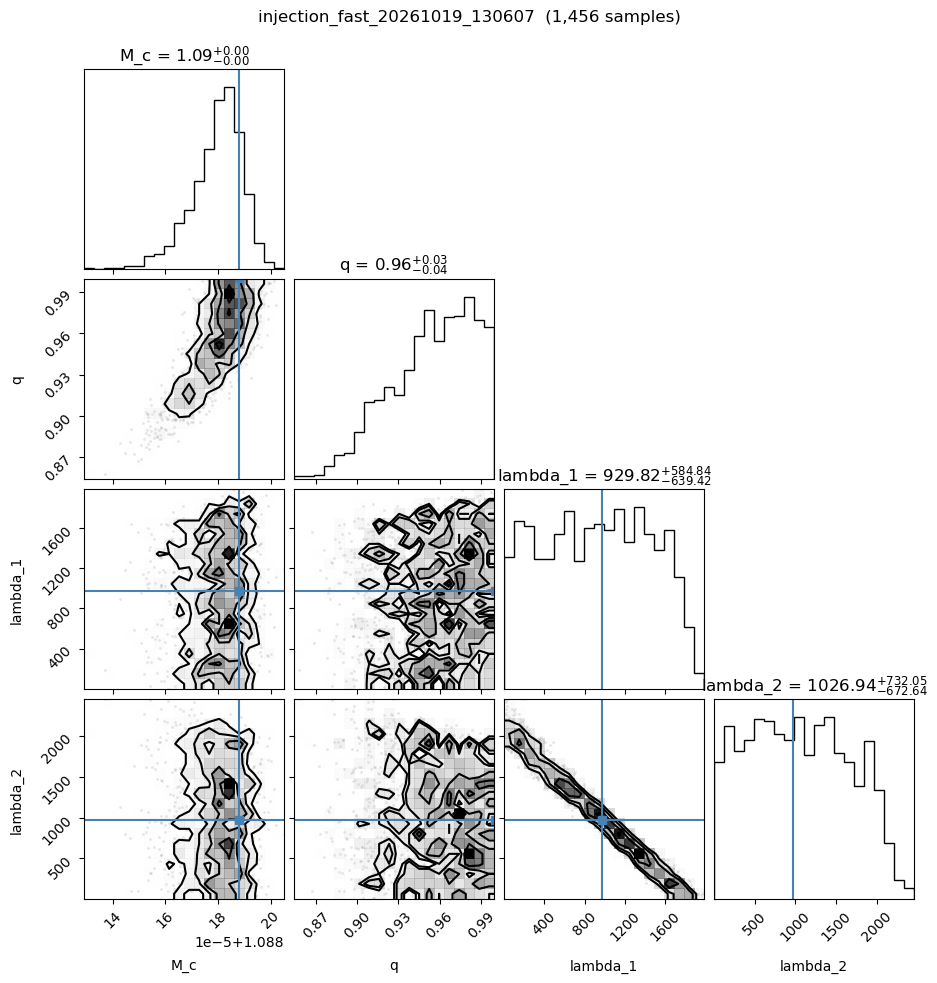

In [6]:
RUN = "injection_fast_20261019_130607"  # folder name in runs/

import json
from pathlib import Path

import corner
import matplotlib.pyplot as plt
import numpy as np

run_dir = Path("runs") / RUN
samples = np.load(run_dir / "samples.npz")
names = [k for k in samples.files if k != "log_likelihood"]

config = json.loads((run_dir / "config.json").read_text()) if (run_dir / "config.json").exists() else {}
truths = [config["injection"]["truths"].get(k) for k in names] if config else None
labels = [config.get("parameter_labels", {}).get(k, k) for k in names]

fig = corner.corner(np.stack([samples[k] for k in names]).T, labels=labels, truths=truths, show_titles=True)
fig.suptitle(f"{RUN}  ({len(samples[names[0]]):,} samples)", y=1.02)
plt.show()